# Machine Learning Hybrid and Sentiment-Based Models to Predict Short-Term Stock Market Volatility


| # | Model | Type | Configuration |
|---|-------|------|---------------|
| 1 | Logistic Regression | Classification | Technical-Only & Hybrid |
| 2 | Decision Tree | Classification | Technical-Only & Hybrid |
| 3 | Random Forest | Classification | Technical-Only & Hybrid |
| 4 | XGBoost (Gradient Boosting) | Classification | Technical-Only & Hybrid |
| 5 | SVM (Support Vector Machine) | Classification | Technical-Only & Hybrid |

**Technical-Only** = baseline features (price + technical indicators)  
**Hybrid** = baseline + sentiment features (VADER + TextBlob)

<a id='1'></a>
## 1. Setup & Configuration

Install required packages and configure the environment. GPU is auto-detected for XGBoost acceleration on Kaggle.

In [1]:
%%time
import subprocess, sys

# Install packages (silent mode for clean output)
for pkg in ['xgboost', 'joblib']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

print('Dependencies installed successfully.')

Dependencies installed successfully.
CPU times: user 735 µs, sys: 990 µs, total: 1.72 ms
Wall time: 6.95 s


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import warnings
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, classification_report, confusion_matrix
)
from scipy.stats import wilcoxon
import xgboost as xgb

warnings.filterwarnings('ignore')
np.random.seed(42)

# Plotting aesthetics
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

# GPU Detection for XGBoost
GPU_AVAILABLE = False
try:
    import torch
    GPU_AVAILABLE = torch.cuda.is_available()
    if GPU_AVAILABLE:
        print(f'GPU Detected: {torch.cuda.get_device_name(0)}')
except ImportError:
    pass

if not GPU_AVAILABLE:
    try:
        result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
        if result.returncode == 0:
            GPU_AVAILABLE = True
            print('GPU Detected via nvidia-smi')
    except Exception:
        pass

print(f'GPU Available for XGBoost: {GPU_AVAILABLE}')
print('Setup complete.')

GPU Detected: Tesla P100-PCIE-16GB
GPU Available for XGBoost: True
Setup complete.


<a id='2'></a>
## 2. Data Loading & Inspection
Load the preprocessed dataset containing S&P 500 price data merged with Reddit news sentiment scores. The data has been:
- Forward-filled for weekends/holidays
- Enriched with **stationary** technical indicators (returns, relative SMA distances, RSI, relative MACD, relative Bollinger Band distances)
- Enriched with sentiment scores (VADER: compound, pos, neg, neu; TextBlob: polarity, subjectivity)

In [ ]:
%%time
DATA_PATH = None
KAGGLE_INPUT = '/kaggle/input'

if os.path.exists(KAGGLE_INPUT):
    for root, dirs, files in os.walk(KAGGLE_INPUT):
        for f in files:
            if f == 'balanced_preprocessed_data.parquet':
                DATA_PATH = os.path.join(root, f)
                break
        if DATA_PATH:
            break
    OUTPUT_DIR = '/kaggle/working'
else:
    DATA_PATH = 'datasets/balanced_preprocessed_data.parquet'
    OUTPUT_DIR = '.'

print(f'Data path: {DATA_PATH}')
print(f'Output dir: {OUTPUT_DIR}')

df = pd.read_parquet(DATA_PATH)

print(f'\nDataset Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
print(f'Date Range: {df["Date"].min()} to {df["Date"].max()}')
print(f'Number of Tickers: {df["Ticker"].nunique()}')
print(f'\nData Types:')
print(df.dtypes)
print(f'\nSample Data:')
df.head()

Data path: /kaggle/input/datasets/ammarshafiq/ainainz/balanced_preprocessed_data.parquet
Output dir: /kaggle/working

Dataset Shape: (912424, 19)
Columns: ['Date', 'Ticker', 'Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'Target', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD', 'neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity']
Date Range: 2008-06-08 00:00:00 to 2016-07-01 00:00:00
Number of Tickers: 486

Data Types:
Date             datetime64[ns]
Ticker                   object
Daily_Return            float64
Open_Return             float64
High_Return             float64
Volume_Change           float64
Target                    int64
SMA_5_Dist              float64
SMA_20_Dist             float64
RSI_14                  float64
BB_Upper_Dist           float64
BB_Lower_Dist           float64
MACD                    float64
neg                     float64
neu                     float64
pos                     float64
compound

,Date,Ticker,Daily_Return,Open_Return,High_Return,Volume_Change,Target,SMA_5_Dist,SMA_20_Dist,RSI_14,BB_Upper_Dist,BB_Lower_Dist,MACD,neg,neu,pos,compound,polarity,subjectivity
0,2009-07-01,WAT,-0.003303,0.007595,0.000387,0.079554,0,0.000976,0.034389,84.412441,-0.018107,0.092815,0.026417,0.122,0.824,0.053,-0.9792,-0.003559,0.450688
1,2010-12-16,HUM,0.008428,-0.024329,-0.011807,-0.076459,1,-0.012558,-0.024503,25.254560,-0.047501,-0.000366,-0.008364,0.201,0.700,0.099,-0.9923,-0.066118,0.321098
2,2013-03-22,LEN,-0.006369,-0.018476,-0.018664,-0.469387,0,-0.001470,0.015723,53.546105,-0.027692,0.063196,0.015320,0.188,0.754,0.058,-0.9969,0.044202,0.280672
3,2009-10-23,SHW,-0.001542,0.000000,0.005273,-0.119306,0,-0.018696,-0.045450,31.737214,-0.101113,0.017562,-0.005510,0.107,0.826,0.068,-0.9649,0.074654,0.400533
4,2013-06-24,WFC,-0.028320,-0.003937,-0.016990,-0.200781,1,-0.018592,-0.020657,37.563433,-0.043482,0.003284,0.002684,0.231,0.714,0.055,-0.9971,0.072769,0.427793


<a id='3'></a>
## 3. Target Engineering

### Critical Design Decision: Per-Ticker Grouping

The target variable represents whether the **next day's closing price is higher than today's** (1 = Up, 0 = Down).

**Why `.groupby('Ticker')` is essential:** The dataset is structured with multiple tickers stacked sequentially. Without grouping, a naive `.shift(-1)` would compare the **last row of Ticker A** with the **first row of Ticker B**, producing corrupted labels at every ticker boundary. The `groupby('Ticker')` ensures the shift operation stays within each individual stock's timeline.

In [6]:
print('Engineering target variable...')
df.sort_values(['Ticker', 'Date'], inplace=True)

if 'Target' in df.columns:
    print('  Target column found in preprocessed data. Using it directly.')
    TARGET_COL = 'Target'
else:
    print('  Target column not found. Computing per-ticker next-day direction from Daily_Return...')
    # Daily_Return is already computed; next-day direction = sign of next-day Daily_Return
    df['Target'] = df.groupby('Ticker')['Daily_Return'].transform(
        lambda x: (x.shift(-1) > 0).astype(float)
    )
    df.dropna(subset=['Target'], inplace=True)
    df['Target'] = df['Target'].astype(int)
    TARGET_COL = 'Target'

print(f'\nDataset shape after target engineering: {df.shape}')
print(f'\nTarget Distribution (Next-Day Direction):')
target_counts = df[TARGET_COL].value_counts()
total = len(df)
print(f'  Up   (1): {target_counts.get(1, 0):>10,} ({target_counts.get(1, 0)/total*100:.2f}%)')
print(f'  Down (0): {target_counts.get(0, 0):>10,} ({target_counts.get(0, 0)/total*100:.2f}%)')
print(f'  Class Ratio (Up/Down): {target_counts.get(1,0)/max(target_counts.get(0,1),1):.3f}')

Engineering target variable...
  Target column found in preprocessed data. Using it directly.

Dataset shape after target engineering: (912424, 19)

Target Distribution (Next-Day Direction):
  Up   (1):    456,212 (50.00%)
  Down (0):    456,212 (50.00%)
  Class Ratio (Up/Down): 1.000


<a id='4'></a>
## 4. Feature Definitions & Temporal Train/Test Split

Two feature sets are defined (as per the research proposal):

| Configuration | Features | Count |
|--------------|----------|-------|
| **Technical-Only (Baseline)** | Daily_Return, Open_Return, High_Return, Volume_Change, SMA_5_Dist, SMA_20_Dist, RSI_14, BB_Upper_Dist, BB_Lower_Dist, MACD | 10 |
| **Hybrid** | Technical + neg, neu, pos, compound, polarity, subjectivity | 16 |

### Critical Design Decision: Date-Based Temporal Split

A **temporal 70/30 split by Date** is used. The split is performed on **unique dates**, ensuring that for any given date, **all tickers** on that date fall into the same partition. This prevents:
- Future data leaking into training
- Entire tickers being isolated to only train or only test (which would mean the model has never seen a single day of data for some companies)

In [ ]:
TECHNICAL_FEATURES = [
    'Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change',
    'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14',
    'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD'
]

SENTIMENT_FEATURES = [
    'neg', 'neu', 'pos', 'compound',  # VADER
    'polarity', 'subjectivity'         # TextBlob
]

HYBRID_FEATURES = TECHNICAL_FEATURES + SENTIMENT_FEATURES

TARGET = 'Target'

print(f'Technical features ({len(TECHNICAL_FEATURES)}): {TECHNICAL_FEATURES}')
print(f'Sentiment features ({len(SENTIMENT_FEATURES)}): {SENTIMENT_FEATURES}')
print(f'Hybrid features ({len(HYBRID_FEATURES)}): {HYBRID_FEATURES}')

# Temporal 70/30 Split BY DATE (IMP: not by row index)
df['Date'] = pd.to_datetime(df['Date'])
unique_dates = sorted(df['Date'].unique())
split_idx = int(len(unique_dates) * 0.7)
split_date = unique_dates[split_idx]

# Split chronologically: ALL tickers present in both train and test
train_df = df[df['Date'] < split_date].copy()
test_df  = df[df['Date'] >= split_date].copy()

print(f'\n{"="*60}')
print(f'  TEMPORAL SPLIT SUMMARY (by Date)')
print(f'{"="*60}')
print(f'  Split Date:    {split_date}')
print(f'  Training Set:  {train_df.shape[0]:>10,} rows  ({train_df["Date"].min()} to {train_df["Date"].max()})')
print(f'  Test Set:      {test_df.shape[0]:>10,} rows  ({test_df["Date"].min()} to {test_df["Date"].max()})')
print(f'  Ratio:         {train_df.shape[0]/len(df)*100:.1f}% / {test_df.shape[0]/len(df)*100:.1f}%')
print(f'  Train tickers: {train_df["Ticker"].nunique()}')
print(f'  Test tickers:  {test_df["Ticker"].nunique()}')
print(f'  Overlap:       {len(set(train_df["Ticker"]) & set(test_df["Ticker"]))} tickers in both')
print(f'{"="*60}')

X_train_tech   = train_df[TECHNICAL_FEATURES].values
X_test_tech    = test_df[TECHNICAL_FEATURES].values
X_train_hybrid = train_df[HYBRID_FEATURES].values
X_test_hybrid  = test_df[HYBRID_FEATURES].values

y_train = train_df[TARGET].values
y_test  = test_df[TARGET].values

assert not (np.isnan(X_train_tech).any() or np.isinf(X_train_tech).any()),   'NaN/inf in technical training features!'
assert not (np.isnan(X_test_tech).any()  or np.isinf(X_test_tech).any()),    'NaN/inf in technical test features!'
assert not (np.isnan(X_train_hybrid).any() or np.isinf(X_train_hybrid).any()), 'NaN/inf in hybrid training features!'
assert not (np.isnan(X_test_hybrid).any()  or np.isinf(X_test_hybrid).any()),  'NaN/inf in hybrid test features!'
assert set(np.unique(y_train)) == {0, 1},  f'Unexpected train labels: {np.unique(y_train)}'
assert set(np.unique(y_test))  == {0, 1},  f'Unexpected test labels: {np.unique(y_test)}'
print('\nAll feature matrices verified - no NaN/inf values.')
print(f'Train target balance: Up={np.mean(y_train)*100:.1f}% / Down={100-np.mean(y_train)*100:.1f}%')
print(f'Test  target balance: Up={np.mean(y_test)*100:.1f}%  / Down={100-np.mean(y_test)*100:.1f}%')

from sklearn.preprocessing import StandardScaler

scaler_tech = StandardScaler()
X_train_tech   = scaler_tech.fit_transform(X_train_tech)
X_test_tech    = scaler_tech.transform(X_test_tech)

scaler_hybrid = StandardScaler()
X_train_hybrid = scaler_hybrid.fit_transform(X_train_hybrid)
X_test_hybrid  = scaler_hybrid.transform(X_test_hybrid)

print('StandardScaler applied: fitted on training data, transformed train + test.')

Technical features (10): ['Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD']
Sentiment features (6): ['neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity']
Hybrid features (16): ['Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD', 'neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity']

  TEMPORAL SPLIT SUMMARY (by Date)
  Split Date:    2014-01-30 00:00:00
  Training Set:     634,448 rows  (2008-06-08 00:00:00 to 2014-01-29 00:00:00)
  Test Set:         277,976 rows  (2014-01-30 00:00:00 to 2016-07-01 00:00:00)
  Ratio:         69.5% / 30.5%
  Train tickers: 485
  Test tickers:  486
  Overlap:       485 tickers in both

All feature matrices verified - no NaN/inf values.
Train target balance: Up=49.1% / Down=50.9%
Test  target balance: Up=52.0%  / Down=48.0%
StandardScaler applied: fitted on 

<a id='5'></a>
## 5. Helper Functions

Utility functions for model evaluation and visualisation.

In [8]:
def evaluate_model(y_true, y_pred, model_name, config_name):
    """
    Evaluate a classification model and return a metrics dictionary.
    Reports: Directional Accuracy, Precision, Recall, F1-Score.
    """
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    print(f'\n{"="*60}')
    print(f'  {model_name} -- {config_name}')
    print(f'{"="*60}')
    print(f'  Directional Accuracy : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  Precision (weighted) : {prec:.4f}')
    print(f'  Recall (weighted)    : {rec:.4f}')
    print(f'  F1-Score (weighted)  : {f1:.4f}')
    
    # Check for degenerate predictions (all same class)
    unique_preds = np.unique(y_pred)
    if len(unique_preds) == 1:
        print(f'  WARNING: Model predicted only class {unique_preds[0]}!')
    
    print(f'\n  Classification Report:')
    print(classification_report(y_true, y_pred, target_names=['Down (0)', 'Up (1)']))
    
    return {
        'Model': model_name,
        'Configuration': config_name,
        'Directional_Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1_Score': f1
    }


def plot_confusion_matrix(y_true, y_pred, title, ax):
    """Plot a confusion matrix heatmap on the given axes."""
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=ax,
                xticklabels=['Down', 'Up'], yticklabels=['Down', 'Up'])
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')


print('Helper functions defined.')

Helper functions defined.


<a id='6'></a>
## 6. Model Training

Each of the five model families is trained on both the **Technical-Only** and **Hybrid** feature sets.

- **SVM** is trained on a subsample due to O(n^2) complexity.

### Why Logistic Regression (not Linear Regression)
The prediction task is **binary classification** (Up/Down direction). Linear Regression produces unbounded continuous outputs, which cannot be meaningfully evaluated with classification metrics. Logistic Regression is the correct model for binary classification, it directly optimises for the decision boundary and outputs calibrated probabilities.

In [9]:
# Storage for results, models, and predictions
results     = []   # List of metric dicts
models      = {}   # Trained model objects
predictions = {}   # Test-set predictions
train_times = {}   # Training durations

print('Storage initialised.')

Storage initialised.


### 6.1 Logistic Regression

Logistic Regression with `max_iter=1000` for convergence on the large dataset. Unlike Linear Regression, this model directly outputs binary class predictions optimised for the classification boundary.

In [ ]:
%%time
print('=' * 60)
print('  TRAINING: Logistic Regression')
print('=' * 60)

LR_PARAMS = {
    'max_iter': 1000,
    'solver': 'lbfgs',
    'random_state': 42,
    'n_jobs': -1
}

# Technical-Only
start = time.time()
lr_tech = LogisticRegression(**LR_PARAMS)
lr_tech.fit(X_train_tech, y_train)
y_pred_lr_tech = lr_tech.predict(X_test_tech)
elapsed = time.time() - start
train_times['lr_technical'] = elapsed
print(f'  [Technical-Only] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_lr_tech, 'Logistic Regression', 'Technical-Only')
results.append(res)
models['lr_technical'] = lr_tech
predictions['lr_technical'] = y_pred_lr_tech

# Hybrid
start = time.time()
lr_hybrid = LogisticRegression(**LR_PARAMS)
lr_hybrid.fit(X_train_hybrid, y_train)
y_pred_lr_hybrid = lr_hybrid.predict(X_test_hybrid)
elapsed = time.time() - start
train_times['lr_hybrid'] = elapsed
print(f'  [Hybrid] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_lr_hybrid, 'Logistic Regression', 'Hybrid')
results.append(res)
models['lr_hybrid'] = lr_hybrid
predictions['lr_hybrid'] = y_pred_lr_hybrid

  TRAINING: Logistic Regression
  [Technical-Only] Training time: 2.56s

  Logistic Regression -- Technical-Only
  Directional Accuracy : 0.5311  (53.11%)
  Precision (weighted) : 0.5309
  Recall (weighted)    : 0.5311
  F1-Score (weighted)  : 0.5310

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.51      0.51      0.51    133369
      Up (1)       0.55      0.56      0.55    144607

    accuracy                           0.53    277976
   macro avg       0.53      0.53      0.53    277976
weighted avg       0.53      0.53      0.53    277976

  [Hybrid] Training time: 2.29s

  Logistic Regression -- Hybrid
  Directional Accuracy : 0.5321  (53.21%)
  Precision (weighted) : 0.5306
  Recall (weighted)    : 0.5321
  F1-Score (weighted)  : 0.5303

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.51      0.47      0.49    133369
      Up (1)       0.55      0.59      0.57    144607

   

### 6.2 Decision Tree Classifier

Decision Tree with regularisation parameters to prevent overfitting on the large dataset.

In [ ]:
%%time
print('=' * 60)
print('  TRAINING: Decision Tree Classifier')
print('=' * 60)

DT_PARAMS = {
    'max_depth': 15,
    'min_samples_split': 50,
    'min_samples_leaf': 20,
    'random_state': 42
}

# Technical-Only
start = time.time()
dt_tech = DecisionTreeClassifier(**DT_PARAMS)
dt_tech.fit(X_train_tech, y_train)
y_pred_dt_tech = dt_tech.predict(X_test_tech)
elapsed = time.time() - start
train_times['dt_technical'] = elapsed
print(f'  [Technical-Only] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_dt_tech, 'Decision Tree', 'Technical-Only')
results.append(res)
models['dt_technical'] = dt_tech
predictions['dt_technical'] = y_pred_dt_tech

# Hybrid
start = time.time()
dt_hybrid = DecisionTreeClassifier(**DT_PARAMS)
dt_hybrid.fit(X_train_hybrid, y_train)
y_pred_dt_hybrid = dt_hybrid.predict(X_test_hybrid)
elapsed = time.time() - start
train_times['dt_hybrid'] = elapsed
print(f'  [Hybrid] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_dt_hybrid, 'Decision Tree', 'Hybrid')
results.append(res)
models['dt_hybrid'] = dt_hybrid
predictions['dt_hybrid'] = y_pred_dt_hybrid

  TRAINING: Decision Tree Classifier
  [Technical-Only] Training time: 14.96s

  Decision Tree -- Technical-Only
  Directional Accuracy : 0.6031  (60.31%)
  Precision (weighted) : 0.6091
  Recall (weighted)    : 0.6031
  F1-Score (weighted)  : 0.5902

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.63      0.42      0.51    133369
      Up (1)       0.59      0.77      0.67    144607

    accuracy                           0.60    277976
   macro avg       0.61      0.60      0.59    277976
weighted avg       0.61      0.60      0.59    277976

  [Hybrid] Training time: 17.42s

  Decision Tree -- Hybrid
  Directional Accuracy : 0.5496  (54.96%)
  Precision (weighted) : 0.5498
  Recall (weighted)    : 0.5496
  F1-Score (weighted)  : 0.5497

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.53      0.54      0.53    133369
      Up (1)       0.57      0.56      0.56    144607

    accu

### 6.3 Random Forest Classifier

An ensemble of 200 decision trees with `n_jobs=-1` for parallel training.

In [ ]:
%%time
print('=' * 60)
print('  TRAINING: Random Forest Classifier')
print('=' * 60)

RF_PARAMS = {
    'n_estimators': 200,
    'max_depth': 15,
    'min_samples_split': 50,
    'min_samples_leaf': 20,
    'random_state': 42,
    'n_jobs': -1
}

# Technical-Only
start = time.time()
rf_tech = RandomForestClassifier(**RF_PARAMS)
rf_tech.fit(X_train_tech, y_train)
y_pred_rf_tech = rf_tech.predict(X_test_tech)
elapsed = time.time() - start
train_times['rf_technical'] = elapsed
print(f'  [Technical-Only] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_rf_tech, 'Random Forest', 'Technical-Only')
results.append(res)
models['rf_technical'] = rf_tech
predictions['rf_technical'] = y_pred_rf_tech

# Hybrid
start = time.time()
rf_hybrid = RandomForestClassifier(**RF_PARAMS)
rf_hybrid.fit(X_train_hybrid, y_train)
y_pred_rf_hybrid = rf_hybrid.predict(X_test_hybrid)
elapsed = time.time() - start
train_times['rf_hybrid'] = elapsed
print(f'  [Hybrid] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_rf_hybrid, 'Random Forest', 'Hybrid')
results.append(res)
models['rf_hybrid'] = rf_hybrid
predictions['rf_hybrid'] = y_pred_rf_hybrid

  TRAINING: Random Forest Classifier
  [Technical-Only] Training time: 229.12s

  Random Forest -- Technical-Only
  Directional Accuracy : 0.6102  (61.02%)
  Precision (weighted) : 0.6175
  Recall (weighted)    : 0.6102
  F1-Score (weighted)  : 0.5970

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.64      0.43      0.51    133369
      Up (1)       0.60      0.78      0.68    144607

    accuracy                           0.61    277976
   macro avg       0.62      0.60      0.59    277976
weighted avg       0.62      0.61      0.60    277976

  [Hybrid] Training time: 247.29s

  Random Forest -- Hybrid
  Directional Accuracy : 0.5897  (58.97%)
  Precision (weighted) : 0.5892
  Recall (weighted)    : 0.5897
  F1-Score (weighted)  : 0.5860

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.59      0.49      0.54    133369
      Up (1)       0.59      0.68      0.63    144607

    ac

### 6.4 XGBoost (Gradient Boosting Machine)

XGBoost with 300 boosting rounds, GPU acceleration (if available).

In [ ]:
%%time
print('=' * 60)
print('  TRAINING: XGBoost Classifier')
print('=' * 60)

# Compute scale_pos_weight for class balance
neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)
scale_pos_weight = neg_count / pos_count
print(f'  Class balance: Down={neg_count:,}  Up={pos_count:,}  scale_pos_weight={scale_pos_weight:.4f}')

XGB_PARAMS = {
    'n_estimators': 300,
    'max_depth': 8,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'scale_pos_weight': scale_pos_weight,
    'random_state': 42,
    'eval_metric': 'logloss',
    'n_jobs': -1
}

if GPU_AVAILABLE:
    XGB_PARAMS['tree_method'] = 'hist'
    XGB_PARAMS['device'] = 'cuda'
    print('  -> Using GPU acceleration (gpu_hist)')
else:
    XGB_PARAMS['tree_method'] = 'hist'
    print('  -> Using CPU (hist method)')

# Technical-Only
start = time.time()
xgb_tech = xgb.XGBClassifier(**XGB_PARAMS)
xgb_tech.fit(X_train_tech, y_train, verbose=False)
y_pred_xgb_tech = xgb_tech.predict(X_test_tech)
elapsed = time.time() - start
train_times['xgb_technical'] = elapsed
print(f'  [Technical-Only] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_xgb_tech, 'XGBoost', 'Technical-Only')
results.append(res)
models['xgb_technical'] = xgb_tech
predictions['xgb_technical'] = y_pred_xgb_tech

# Hybrid
start = time.time()
xgb_hybrid = xgb.XGBClassifier(**XGB_PARAMS)
xgb_hybrid.fit(X_train_hybrid, y_train, verbose=False)
y_pred_xgb_hybrid = xgb_hybrid.predict(X_test_hybrid)
elapsed = time.time() - start
train_times['xgb_hybrid'] = elapsed
print(f'  [Hybrid] Training time: {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_xgb_hybrid, 'XGBoost', 'Hybrid')
results.append(res)
models['xgb_hybrid'] = xgb_hybrid
predictions['xgb_hybrid'] = y_pred_xgb_hybrid

  TRAINING: XGBoost Classifier
  Class balance: Down=322,843  Up=311,605  scale_pos_weight=1.0361
  -> Using GPU acceleration (gpu_hist)
  [Technical-Only] Training time: 2.49s

  XGBoost -- Technical-Only
  Directional Accuracy : 0.6073  (60.73%)
  Precision (weighted) : 0.6168
  Recall (weighted)    : 0.6073
  F1-Score (weighted)  : 0.5913

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.64      0.41      0.50    133369
      Up (1)       0.59      0.79      0.68    144607

    accuracy                           0.61    277976
   macro avg       0.62      0.60      0.59    277976
weighted avg       0.62      0.61      0.59    277976

  [Hybrid] Training time: 2.84s

  XGBoost -- Hybrid
  Directional Accuracy : 0.5372  (53.72%)
  Precision (weighted) : 0.5496
  Recall (weighted)    : 0.5372
  F1-Score (weighted)  : 0.5259

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.51      0.

### 6.5 Support Vector Machine (SVM)

SVM with RBF kernel. Due to SVM's O(n^2) to O(n^3) complexity, training uses a **systematic time-aware subsample** while prediction is on the **full test set** for fair comparison.

- Sampling preserves temporal ordering (evenly spaced indices)
- `cache_size=2000` (MB) speeds up kernel computations

In [ ]:
%%time
print('=' * 60)
print('  TRAINING: Support Vector Machine (SVM)')
print('=' * 60)

# Subsample training data for SVM feasibility
SVM_SAMPLE_SIZE = min(50_000, len(X_train_tech))
print(f'  SVM training sample size: {SVM_SAMPLE_SIZE:,} / {len(X_train_tech):,}')

# Systematic time-aware sampling (evenly spaced to preserve temporal distribution)
svm_indices = np.linspace(0, len(X_train_tech) - 1, SVM_SAMPLE_SIZE, dtype=int)
X_train_svm_tech   = X_train_tech[svm_indices]
X_train_svm_hybrid = X_train_hybrid[svm_indices]
y_train_svm        = y_train[svm_indices]

SVM_PARAMS = {
    'kernel': 'rbf',
    'C': 1.0,
    'gamma': 'scale',
    'random_state': 42,
    'cache_size': 2000
}

# Technical-Only
start = time.time()
svm_tech = SVC(**SVM_PARAMS)
svm_tech.fit(X_train_svm_tech, y_train_svm)
print(f'  [Technical-Only] Training complete. Predicting on full test set...')
y_pred_svm_tech = svm_tech.predict(X_test_tech)
elapsed = time.time() - start
train_times['svm_technical'] = elapsed
print(f'  [Technical-Only] Total time (train + predict): {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_svm_tech, 'SVM (RBF)', 'Technical-Only')
results.append(res)
models['svm_technical'] = svm_tech
predictions['svm_technical'] = y_pred_svm_tech

# Hybrid
start = time.time()
svm_hybrid = SVC(**SVM_PARAMS)
svm_hybrid.fit(X_train_svm_hybrid, y_train_svm)
print(f'  [Hybrid] Training complete. Predicting on full test set...')
y_pred_svm_hybrid = svm_hybrid.predict(X_test_hybrid)
elapsed = time.time() - start
train_times['svm_hybrid'] = elapsed
print(f'  [Hybrid] Total time (train + predict): {elapsed:.2f}s')

res = evaluate_model(y_test, y_pred_svm_hybrid, 'SVM (RBF)', 'Hybrid')
results.append(res)
models['svm_hybrid'] = svm_hybrid
predictions['svm_hybrid'] = y_pred_svm_hybrid

  TRAINING: Support Vector Machine (SVM)
  SVM training sample size: 50,000 / 634,448
  [Technical-Only] Training complete. Predicting on full test set...
  [Technical-Only] Total time (train + predict): 587.11s

  SVM (RBF) -- Technical-Only
  Directional Accuracy : 0.5809  (58.09%)
  Precision (weighted) : 0.6368
  Recall (weighted)    : 0.5809
  F1-Score (weighted)  : 0.5163

  Classification Report:
              precision    recall  f1-score   support

    Down (0)       0.72      0.21      0.32    133369
      Up (1)       0.56      0.93      0.70    144607

    accuracy                           0.58    277976
   macro avg       0.64      0.57      0.51    277976
weighted avg       0.64      0.58      0.52    277976

  [Hybrid] Training complete. Predicting on full test set...
  [Hybrid] Total time (train + predict): 593.08s

  SVM (RBF) -- Hybrid
  Directional Accuracy : 0.5668  (56.68%)
  Precision (weighted) : 0.5819
  Recall (weighted)    : 0.5668
  F1-Score (weighted)  : 0.

## 7. Results Summary

Consolidated performance metrics across all model families and configurations.

In [ ]:
# Build results DataFrame
results_df = pd.DataFrame(results)

# Format for display
display_df = results_df.copy()
display_df['Directional_Accuracy'] = display_df['Directional_Accuracy'].apply(lambda x: f'{x:.4f} ({x*100:.2f}%)')
display_df['Precision'] = display_df['Precision'].apply(lambda x: f'{x:.4f}')
display_df['Recall']    = display_df['Recall'].apply(lambda x: f'{x:.4f}')
display_df['F1_Score']  = display_df['F1_Score'].apply(lambda x: f'{x:.4f}')

print('=' * 90)
print('  COMPLETE RESULTS TABLE -- All Models x All Configurations')
print('=' * 90)
print(display_df.to_string(index=False))
print('=' * 90)

# Compute Improvement (Hybrid vs Technical)
print('\n\n=== IMPROVEMENT ANALYSIS (Hybrid - Technical) ===\n')
model_names_unique = results_df['Model'].unique()

improvement_data = []
for model_name in model_names_unique:
    tech_row   = results_df[(results_df['Model'] == model_name) & (results_df['Configuration'] == 'Technical-Only')]
    hybrid_row = results_df[(results_df['Model'] == model_name) & (results_df['Configuration'] == 'Hybrid')]
    
    if len(tech_row) > 0 and len(hybrid_row) > 0:
        tech_acc   = tech_row['Directional_Accuracy'].values[0]
        hybrid_acc = hybrid_row['Directional_Accuracy'].values[0]
        diff = (hybrid_acc - tech_acc) * 100  # percentage points
        meets_threshold = 'YES' if diff >= 3.0 else 'No'
        
        improvement_data.append({
            'Model': model_name,
            'Technical_Acc': f'{tech_acc*100:.2f}%',
            'Hybrid_Acc': f'{hybrid_acc*100:.2f}%',
            'Improvement_pp': f'{diff:+.2f} pp',
            'Meets_3pp_Threshold': meets_threshold
        })
        print(f'  {model_name:25s}  Tech: {tech_acc*100:.2f}%  ->  Hybrid: {hybrid_acc*100:.2f}%  |  D = {diff:+.2f} pp  |  {meets_threshold}')

improvement_df = pd.DataFrame(improvement_data)

# Training Times
print('\n\n=== TRAINING TIMES ===\n')
for key, duration in sorted(train_times.items()):
    print(f'  {key:25s}: {duration:8.2f}s')

  COMPLETE RESULTS TABLE -- All Models x All Configurations
              Model  Configuration Directional_Accuracy Precision Recall F1_Score
Logistic Regression Technical-Only      0.5311 (53.11%)    0.5309 0.5311   0.5310
Logistic Regression         Hybrid      0.5321 (53.21%)    0.5306 0.5321   0.5303
      Decision Tree Technical-Only      0.6031 (60.31%)    0.6091 0.6031   0.5902
      Decision Tree         Hybrid      0.5496 (54.96%)    0.5498 0.5496   0.5497
      Random Forest Technical-Only      0.6102 (61.02%)    0.6175 0.6102   0.5970
      Random Forest         Hybrid      0.5897 (58.97%)    0.5892 0.5897   0.5860
            XGBoost Technical-Only      0.6073 (60.73%)    0.6168 0.6073   0.5913
            XGBoost         Hybrid      0.5372 (53.72%)    0.5496 0.5372   0.5259
          SVM (RBF) Technical-Only      0.5809 (58.09%)    0.6368 0.5809   0.5163
          SVM (RBF)         Hybrid      0.5668 (56.68%)    0.5819 0.5668   0.5266


=== IMPROVEMENT ANALYSIS (Hybrid - T

## 8. Confusion Matrices

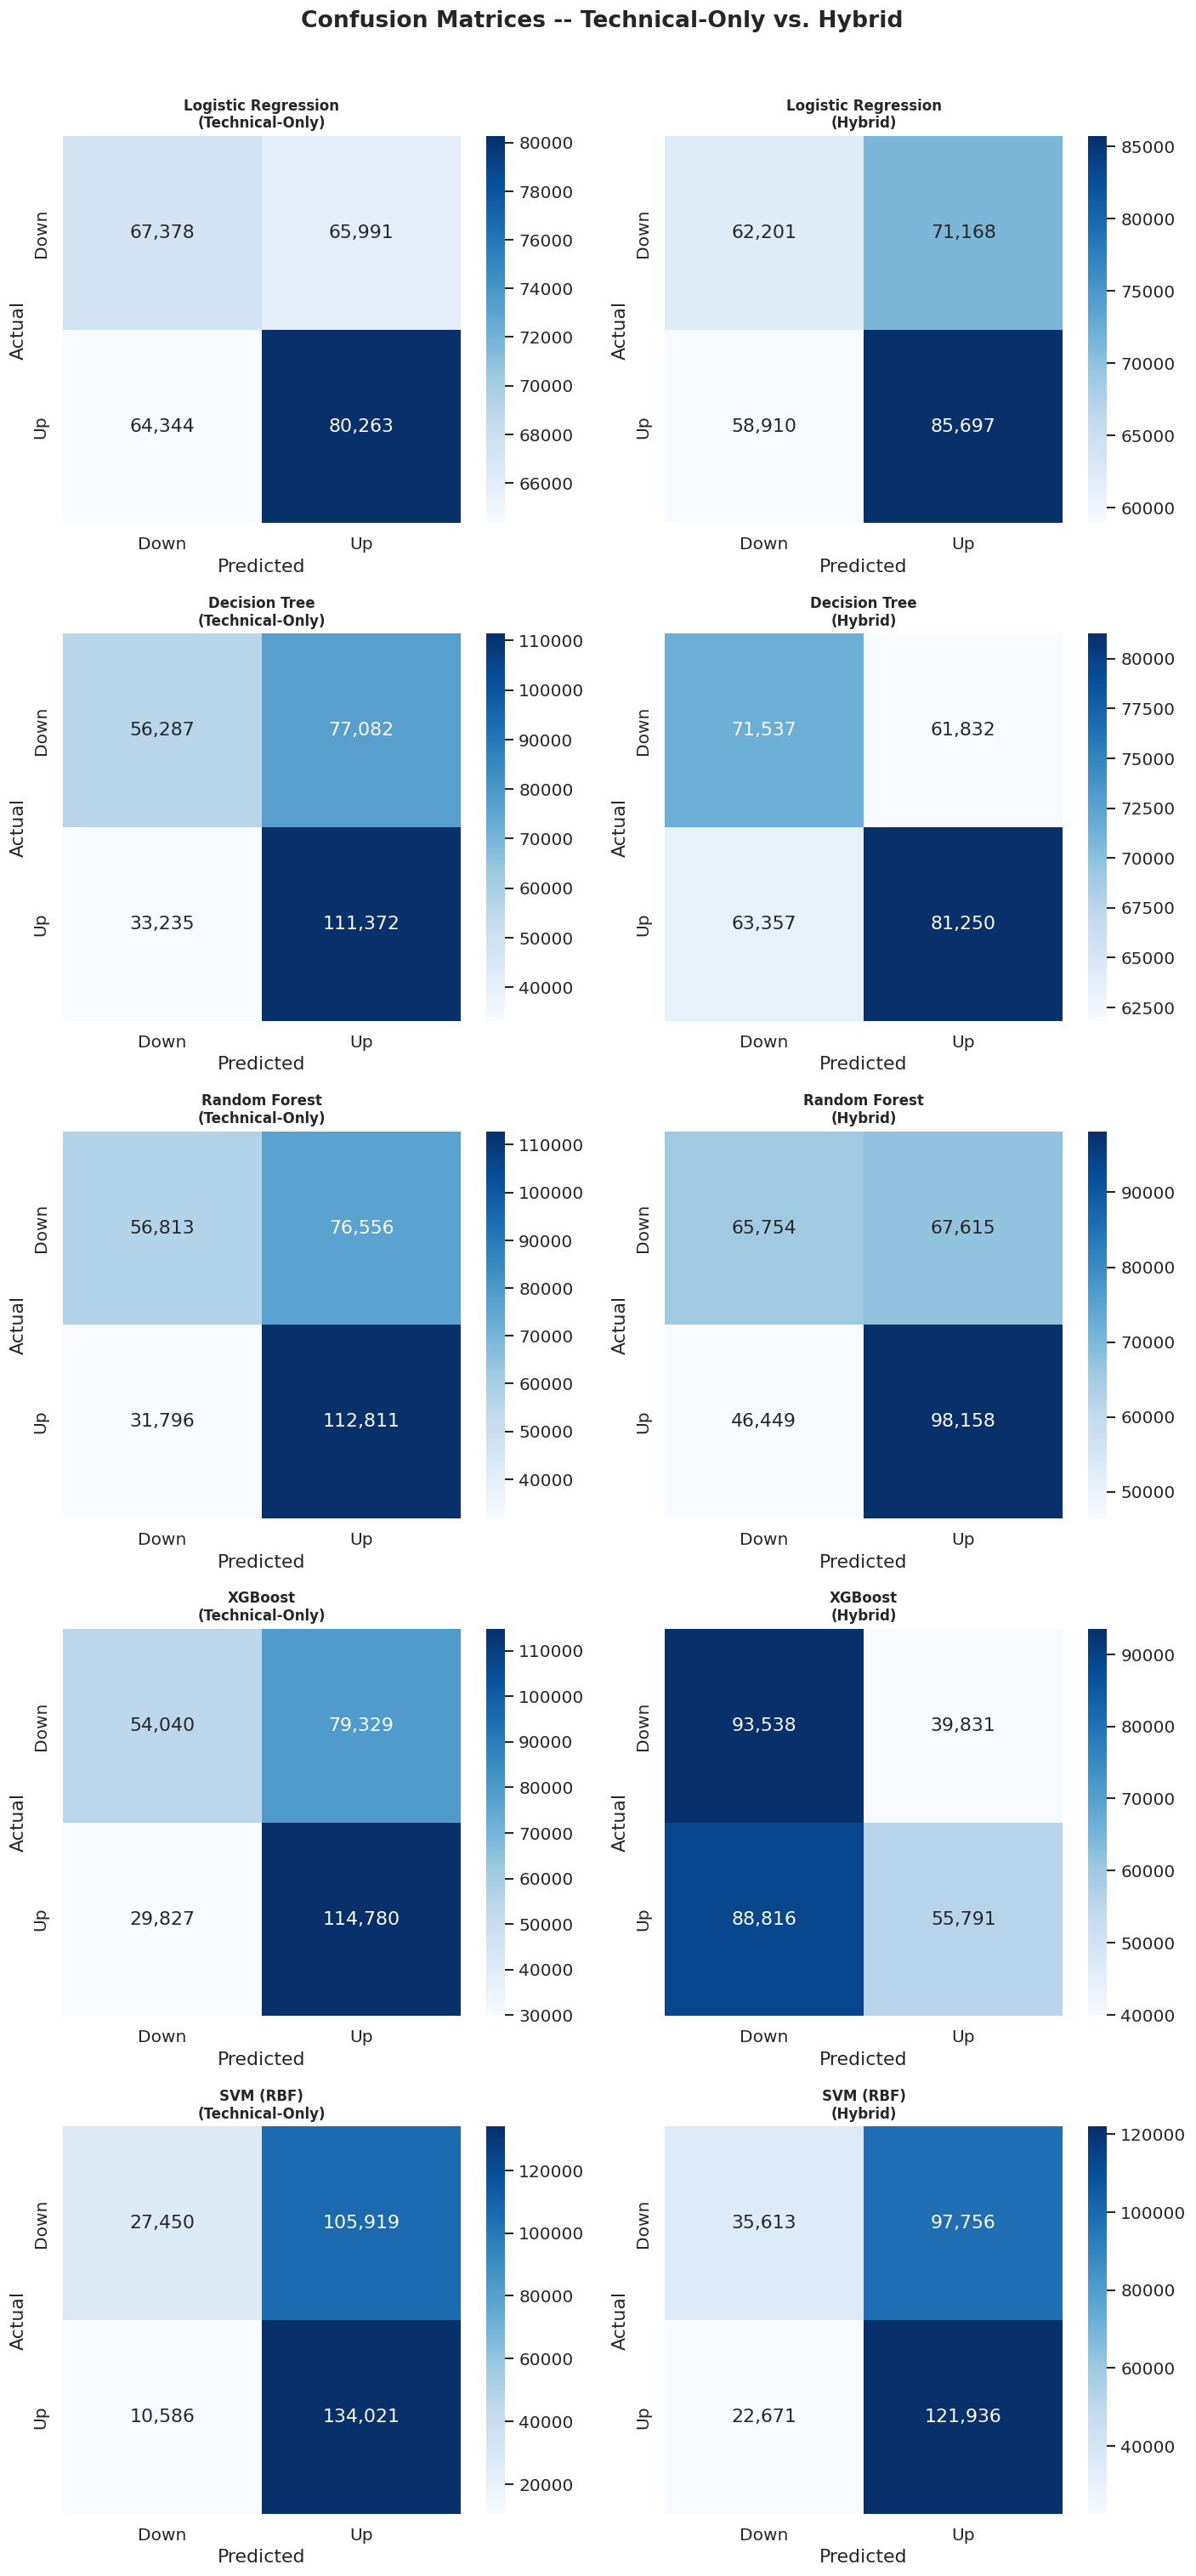

Confusion matrices saved.


In [17]:
model_display_names = [
    ('lr_technical',  'lr_hybrid',  'Logistic Regression'),
    ('dt_technical',  'dt_hybrid',  'Decision Tree'),
    ('rf_technical',  'rf_hybrid',  'Random Forest'),
    ('xgb_technical', 'xgb_hybrid', 'XGBoost'),
    ('svm_technical', 'svm_hybrid', 'SVM (RBF)'),
]

fig, axes = plt.subplots(5, 2, figsize=(12, 25))
fig.suptitle('Confusion Matrices -- Technical-Only vs. Hybrid', fontsize=16, fontweight='bold', y=1.01)

for i, (tech_key, hybrid_key, name) in enumerate(model_display_names):
    plot_confusion_matrix(y_test, predictions[tech_key], f'{name}\n(Technical-Only)', axes[i, 0])
    plot_confusion_matrix(y_test, predictions[hybrid_key], f'{name}\n(Hybrid)', axes[i, 1])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrices.png'), bbox_inches='tight')
plt.show()
print('Confusion matrices saved.')

## 9. Ablation Analysis -- Feature Importance

Feature importance analysis using:
- **Random Forest Gini Impurity** (as specified in the evaluation plan)
- **XGBoost Gain-based importance**

This ablation identifies which sentiment features contribute most to the prediction task, addressing the research question of *whether* and *which* sentiment features matter.

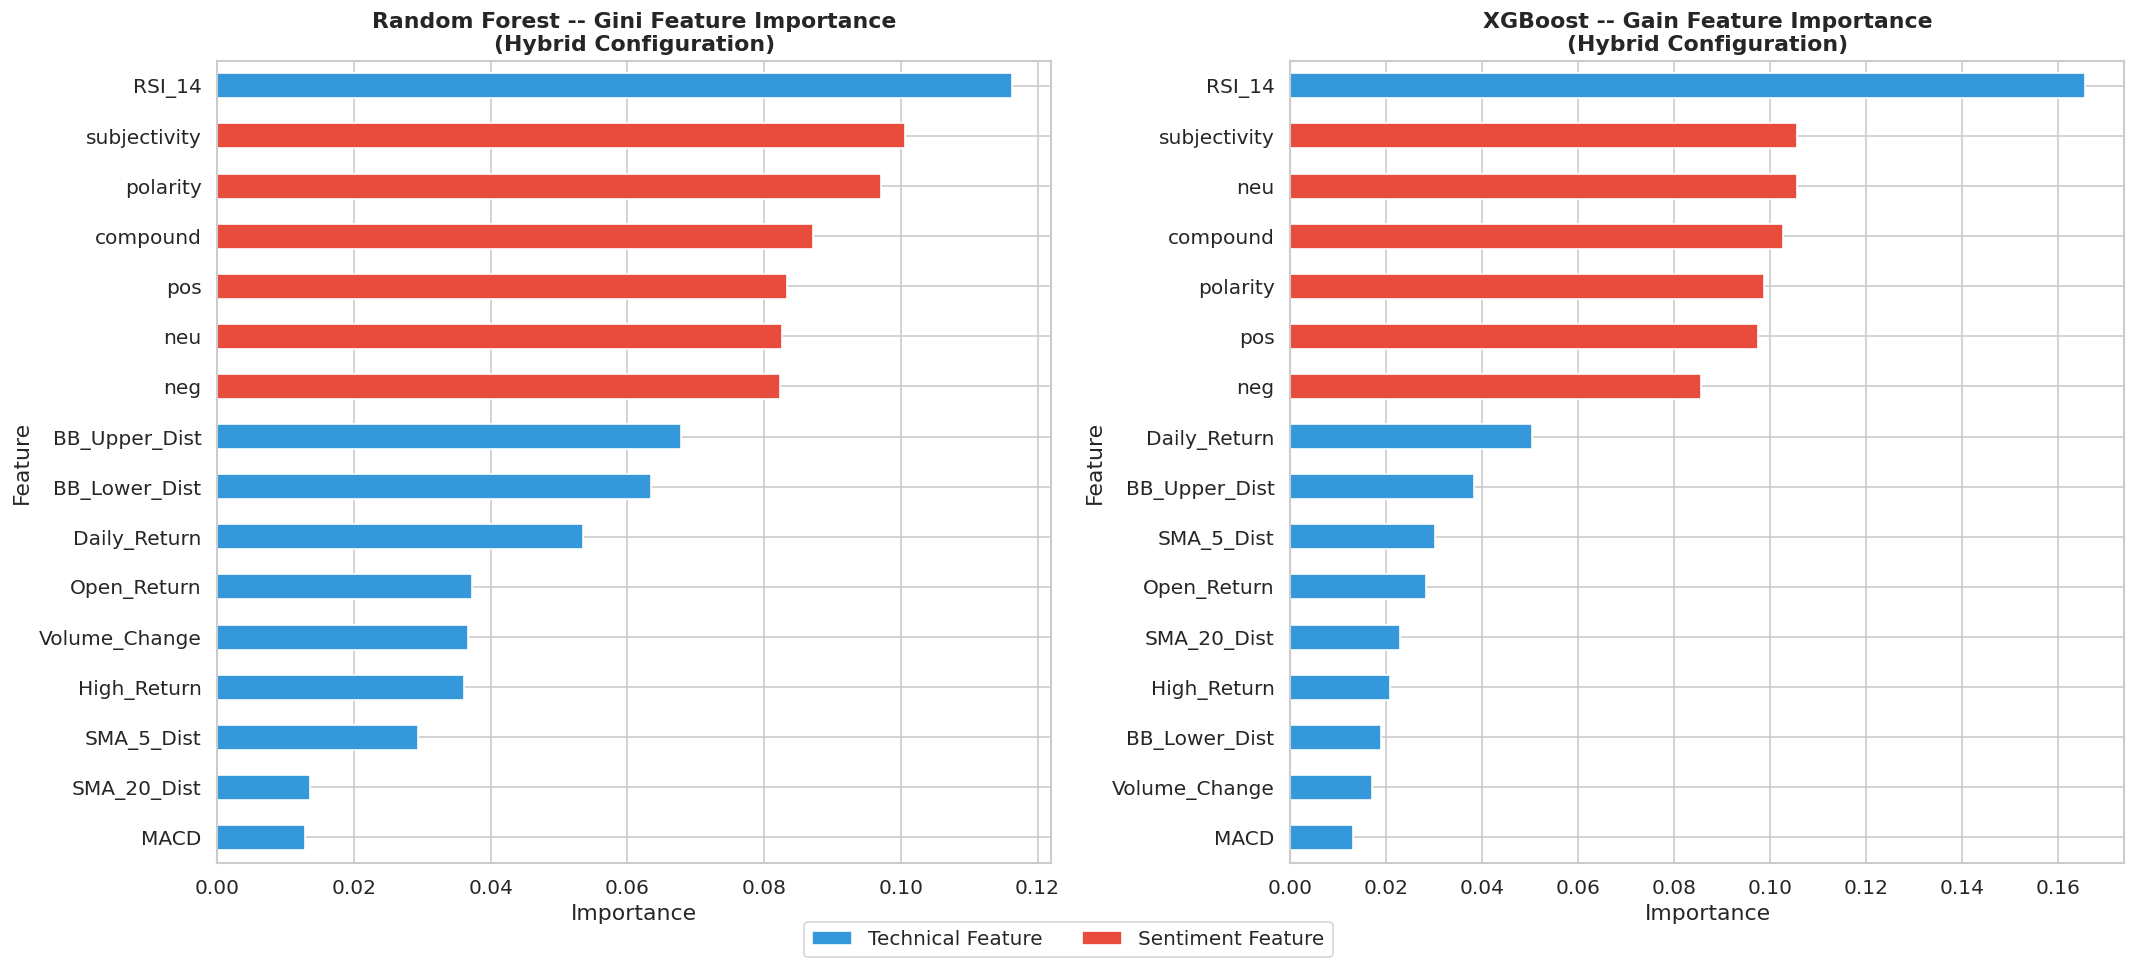


=== SENTIMENT FEATURE IMPORTANCE RANKING ===

Random Forest (Gini):
  subjectivity   : 0.100666
  polarity       : 0.097147
  compound       : 0.087171
  pos            : 0.083318
  neu            : 0.082603
  neg            : 0.082352

XGBoost (Gain):
  subjectivity   : 0.105610
  neu            : 0.105563
  compound       : 0.102699
  polarity       : 0.098567
  pos            : 0.097380
  neg            : 0.085445

Ablation analysis complete.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Random Forest Gini Importance (Hybrid)
rf_importance = pd.DataFrame({
    'Feature': HYBRID_FEATURES,
    'Importance': rf_hybrid.feature_importances_
}).sort_values('Importance', ascending=True)

colors_rf = ['#e74c3c' if f in SENTIMENT_FEATURES else '#3498db' for f in rf_importance['Feature']]

rf_importance.plot.barh(x='Feature', y='Importance', ax=axes[0], color=colors_rf, legend=False)
axes[0].set_title('Random Forest -- Gini Feature Importance\n(Hybrid Configuration)', fontweight='bold')
axes[0].set_xlabel('Importance')

# XGBoost Gain Importance (Hybrid)
xgb_importance = pd.DataFrame({
    'Feature': HYBRID_FEATURES,
    'Importance': xgb_hybrid.feature_importances_
}).sort_values('Importance', ascending=True)

colors_xgb = ['#e74c3c' if f in SENTIMENT_FEATURES else '#3498db' for f in xgb_importance['Feature']]

xgb_importance.plot.barh(x='Feature', y='Importance', ax=axes[1], color=colors_xgb, legend=False)
axes[1].set_title('XGBoost -- Gain Feature Importance\n(Hybrid Configuration)', fontweight='bold')
axes[1].set_xlabel('Importance')

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#3498db', label='Technical Feature'),
                   Patch(facecolor='#e74c3c', label='Sentiment Feature')]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, fontsize=12,
           bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'feature_importance_ablation.png'), bbox_inches='tight')
plt.show()

# Print Importance Rankings
print('\n=== SENTIMENT FEATURE IMPORTANCE RANKING ===')
print('\nRandom Forest (Gini):')
rf_sentiment = rf_importance[rf_importance['Feature'].isin(SENTIMENT_FEATURES)].sort_values('Importance', ascending=False)
for _, row in rf_sentiment.iterrows():
    print(f"  {row['Feature']:15s}: {row['Importance']:.6f}")

print('\nXGBoost (Gain):')
xgb_sentiment = xgb_importance[xgb_importance['Feature'].isin(SENTIMENT_FEATURES)].sort_values('Importance', ascending=False)
for _, row in xgb_sentiment.iterrows():
    print(f"  {row['Feature']:15s}: {row['Importance']:.6f}")

print('\nAblation analysis complete.')

## 10. Statistical Significance -- Wilcoxon Signed-Rank Test

A **paired Wilcoxon signed-rank test** is applied across rolling 3-month evaluation windows to determine whether accuracy differences between Technical-Only and Hybrid configurations are statistically significant (p < 0.05).

This non-parametric test is preferred because we cannot assume the distribution of prediction accuracy across rolling windows is normal.

In [ ]:
# Create Rolling 3-Month Windows on Test Data
test_dates_sorted = np.sort(test_df['Date'].unique())
window_size = pd.Timedelta(days=90)  # ~3 months

windows = []
current_start = pd.Timestamp(test_dates_sorted[0])
end_date = pd.Timestamp(test_dates_sorted[-1])

while current_start < end_date:
    current_end = current_start + window_size
    mask = (test_df['Date'].values >= np.datetime64(current_start)) & \
           (test_df['Date'].values < np.datetime64(current_end))
    if mask.sum() > 100:
        windows.append(mask)
    current_start = current_end

print(f'Number of 3-month evaluation windows: {len(windows)}')

# Run Wilcoxon Test for Each Model
model_pairs = [
    ('Logistic Regression', 'lr_technical',  'lr_hybrid'),
    ('Decision Tree',       'dt_technical',  'dt_hybrid'),
    ('Random Forest',       'rf_technical',  'rf_hybrid'),
    ('XGBoost',             'xgb_technical', 'xgb_hybrid'),
    ('SVM (RBF)',           'svm_technical', 'svm_hybrid'),
]

wilcoxon_results = []

print(f'\n{"="*80}')
print(f'{"WILCOXON SIGNED-RANK TEST RESULTS":^80}')
print(f'{"="*80}')

for model_name, tech_key, hybrid_key in model_pairs:
    tech_accs   = []
    hybrid_accs = []
    
    for mask in windows:
        y_true_w      = y_test[mask]
        tech_pred_w   = predictions[tech_key][mask]
        hybrid_pred_w = predictions[hybrid_key][mask]
        tech_accs.append(accuracy_score(y_true_w, tech_pred_w))
        hybrid_accs.append(accuracy_score(y_true_w, hybrid_pred_w))
    
    tech_accs   = np.array(tech_accs)
    hybrid_accs = np.array(hybrid_accs)
    mean_diff   = np.mean(hybrid_accs - tech_accs) * 100
    
    try:
        # Need non-zero differences for Wilcoxon
        diffs = hybrid_accs - tech_accs
        if np.all(diffs == 0):
            stat, p_value = None, None
            significant = 'N/A (identical)'
        else:
            stat, p_value = wilcoxon(tech_accs, hybrid_accs, alternative='two-sided')
            significant = 'Yes' if p_value < 0.05 else 'No'
    except Exception as e:
        stat, p_value = None, None
        significant = f'N/A ({str(e)[:30]})'
    
    result = {
        'Model': model_name,
        'N_Windows': len(tech_accs),
        'Mean_Tech_Acc': np.mean(tech_accs),
        'Mean_Hybrid_Acc': np.mean(hybrid_accs),
        'Mean_Diff_pp': mean_diff,
        'Wilcoxon_Stat': stat,
        'p_value': p_value,
        'Significant_p05': significant
    }
    wilcoxon_results.append(result)
    
    print(f'\n  {model_name}')
    print(f'  {"-"*40}')
    print(f'    Windows:           {len(tech_accs)}')
    print(f'    Mean Tech Acc:     {np.mean(tech_accs)*100:.2f}%')
    print(f'    Mean Hybrid Acc:   {np.mean(hybrid_accs)*100:.2f}%')
    print(f'    Mean Improvement:  {mean_diff:+.2f} pp')
    if p_value is not None:
        print(f'    Wilcoxon Stat:     {stat:.4f}')
        print(f'    p-value:           {p_value:.6f}')
    print(f'    Significant:       {significant}')

print(f'\n{"="*80}')

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print('\nWilcoxon Test Summary Table:')
print(wilcoxon_df.to_string(index=False))

Number of 3-month evaluation windows: 10

                       WILCOXON SIGNED-RANK TEST RESULTS                        

  Logistic Regression
  ----------------------------------------
    Windows:           10
    Mean Tech Acc:     53.10%
    Mean Hybrid Acc:   53.18%
    Mean Improvement:  +0.08 pp
    Wilcoxon Stat:     27.0000
    p-value:           1.000000
    Significant:       No

  Decision Tree
  ----------------------------------------
    Windows:           10
    Mean Tech Acc:     60.30%
    Mean Hybrid Acc:   54.93%
    Mean Improvement:  -5.36 pp
    Wilcoxon Stat:     1.0000
    p-value:           0.003906
    Significant:       Yes

  Random Forest
  ----------------------------------------
    Windows:           10
    Mean Tech Acc:     61.00%
    Mean Hybrid Acc:   58.92%
    Mean Improvement:  -2.08 pp
    Wilcoxon Stat:     2.0000
    p-value:           0.005859
    Significant:       Yes

  XGBoost
  ----------------------------------------
    Windows:    

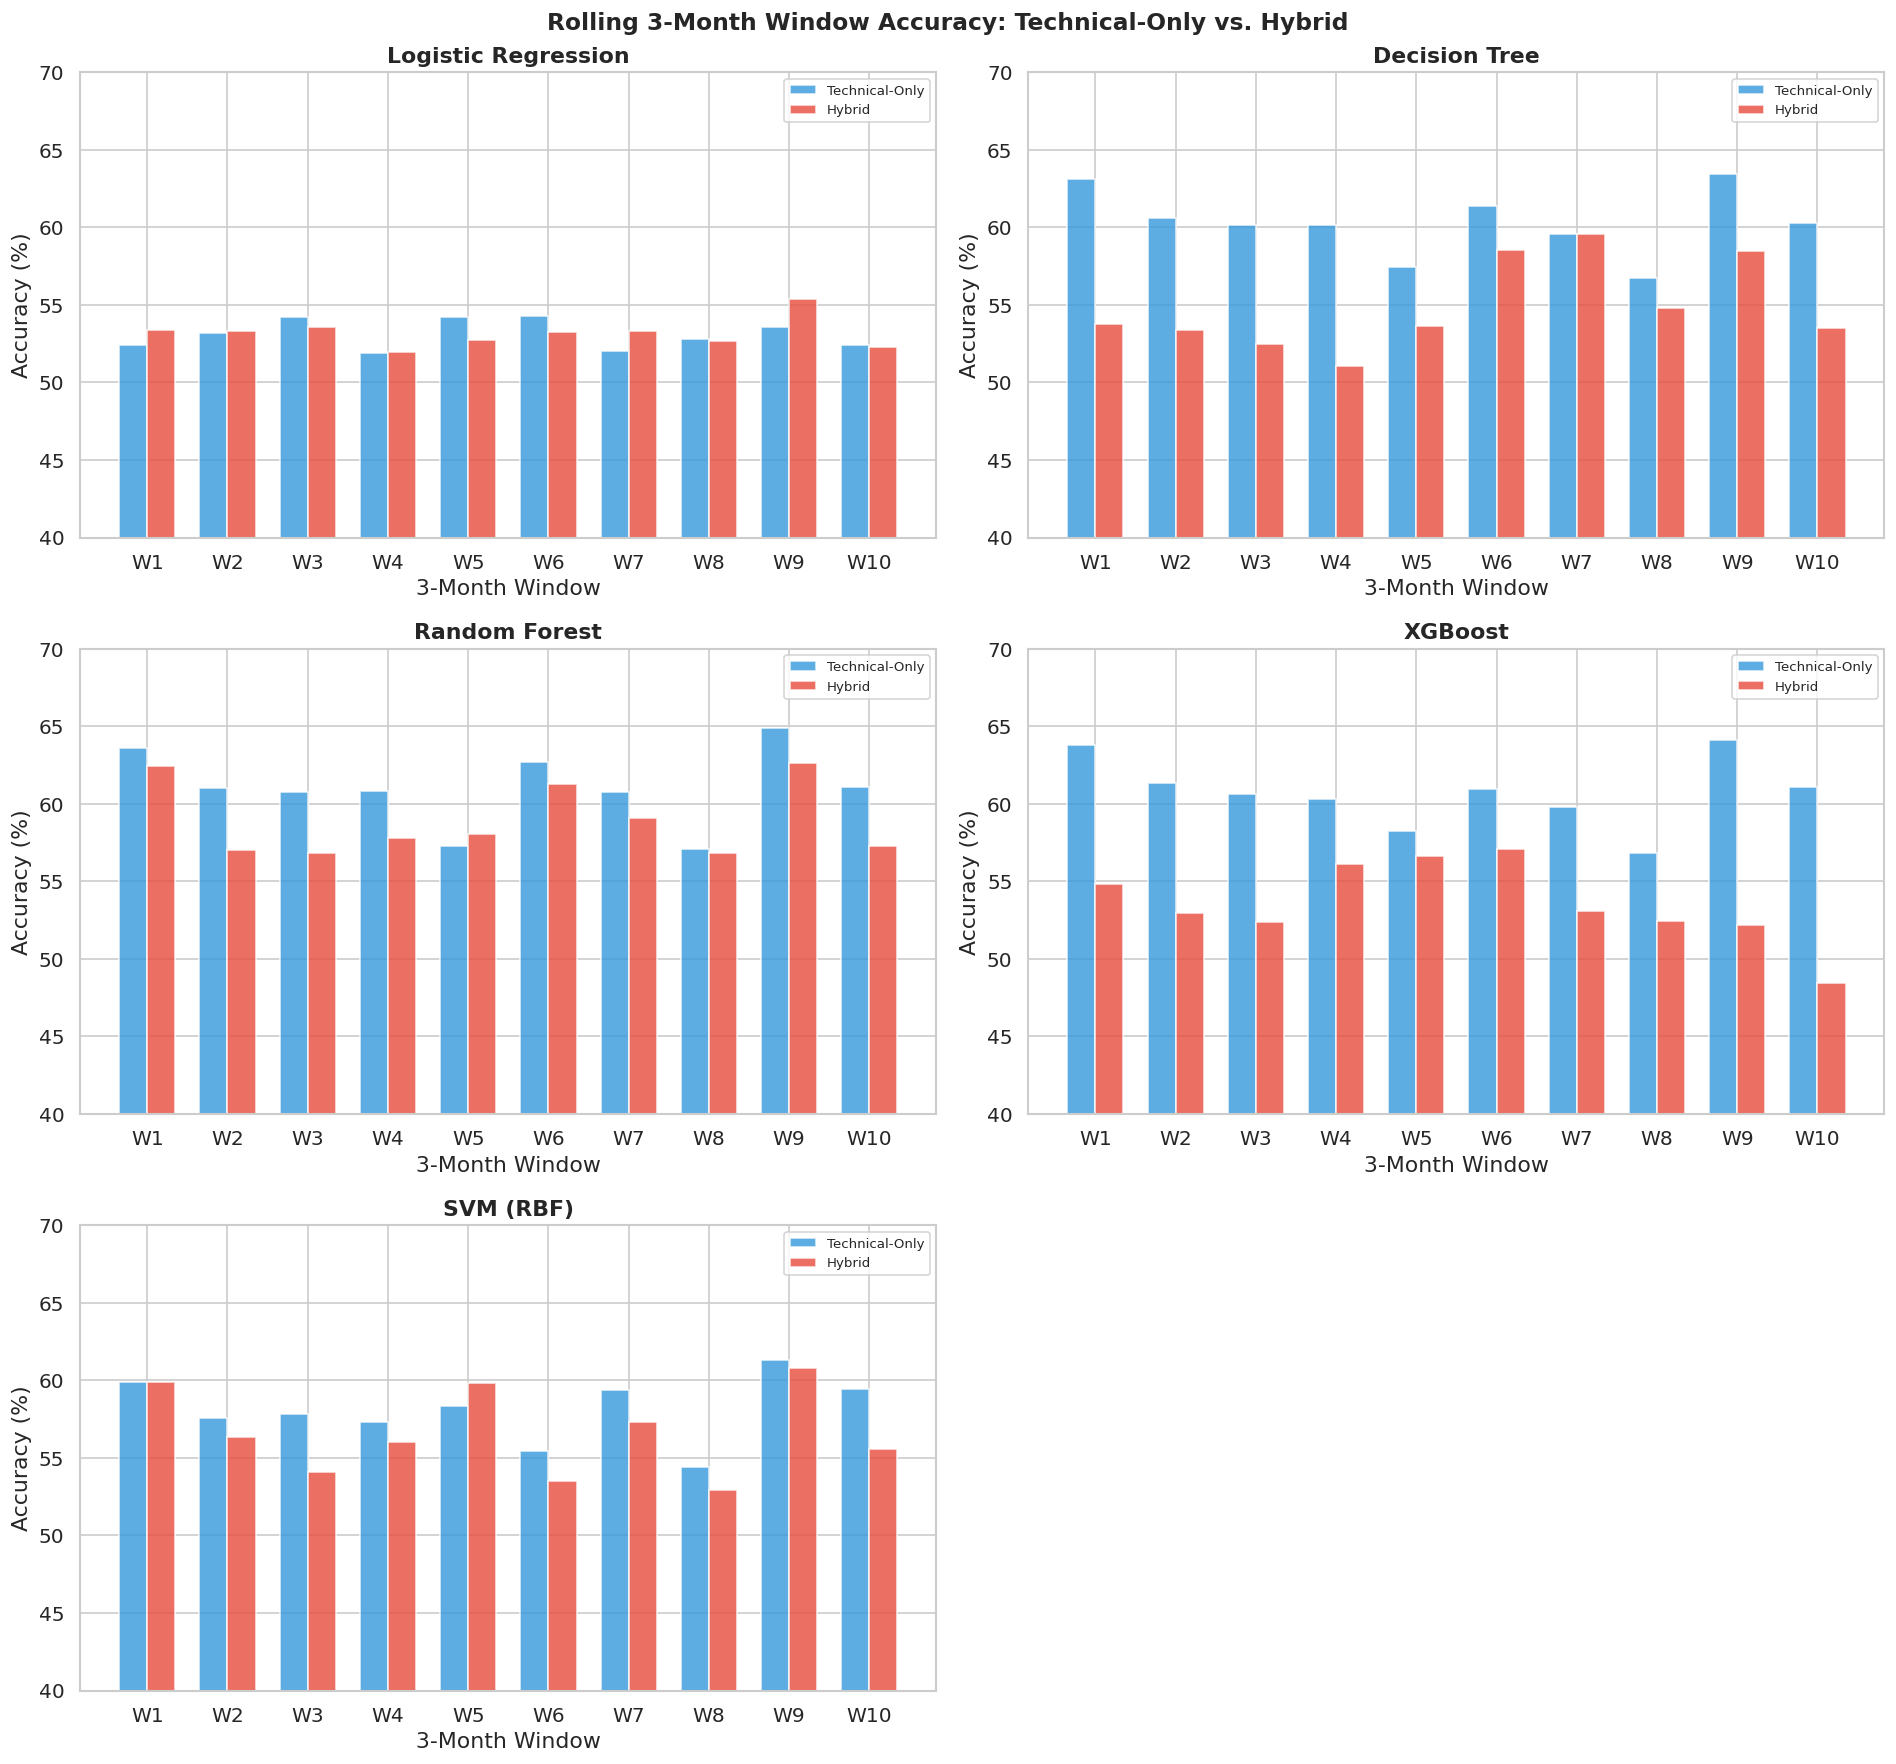

In [ ]:
# Visualise Rolling Window Accuracies
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes_flat = axes.flatten()

window_labels = [f'W{i+1}' for i in range(len(windows))]

for idx, (model_name, tech_key, hybrid_key) in enumerate(model_pairs):
    if idx >= len(axes_flat):
        break
    ax = axes_flat[idx]
    
    tech_accs_plot   = [accuracy_score(y_test[m], predictions[tech_key][m]) for m in windows]
    hybrid_accs_plot = [accuracy_score(y_test[m], predictions[hybrid_key][m]) for m in windows]
    
    x = np.arange(len(windows))
    width = 0.35
    ax.bar(x - width/2, [a*100 for a in tech_accs_plot], width, label='Technical-Only', color='#3498db', alpha=0.8)
    ax.bar(x + width/2, [a*100 for a in hybrid_accs_plot], width, label='Hybrid', color='#e74c3c', alpha=0.8)
    ax.set_title(f'{model_name}', fontweight='bold')
    ax.set_xlabel('3-Month Window')
    ax.set_ylabel('Accuracy (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(window_labels)
    ax.legend(fontsize=8)
    ax.set_ylim(40, 70)

# Hide unused subplot
if len(model_pairs) < len(axes_flat):
    axes_flat[-1].set_visible(False)

fig.suptitle('Rolling 3-Month Window Accuracy: Technical-Only vs. Hybrid', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'rolling_window_accuracy.png'), bbox_inches='tight')
plt.show()

## 11. Comparative Visualisations

Side-by-side visual comparison of model performance across configurations.

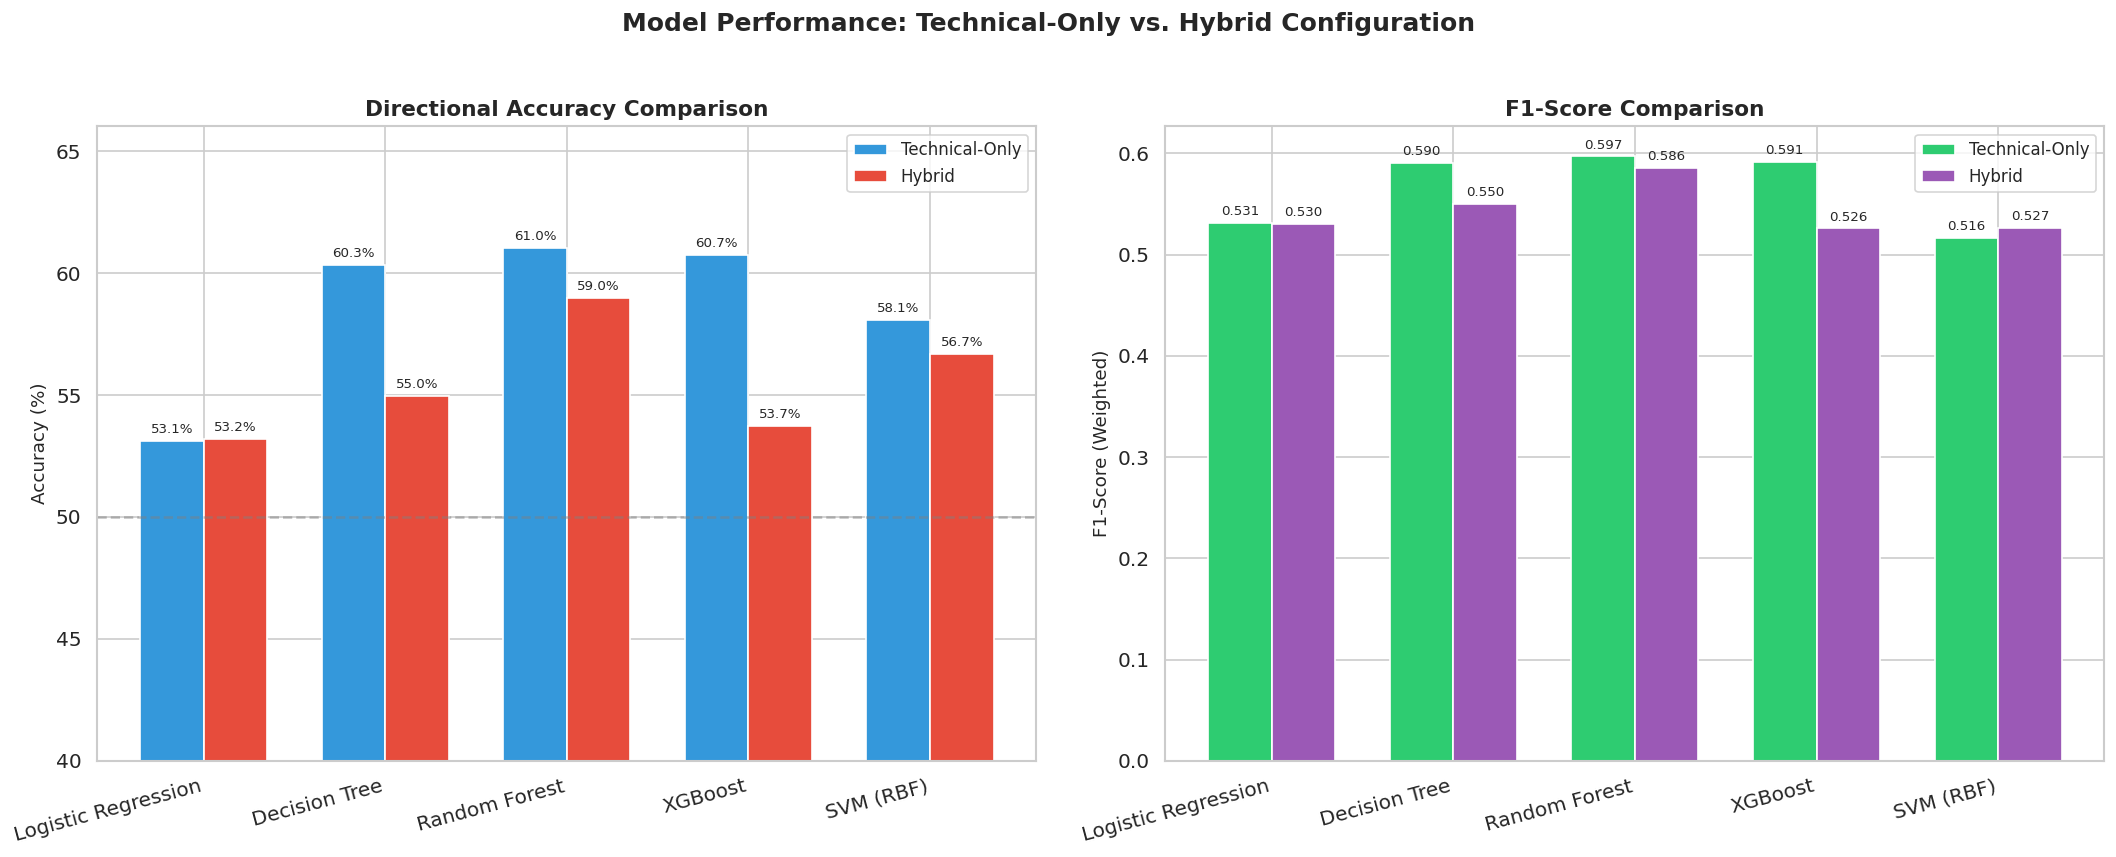

In [ ]:
# Accuracy Comparison Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

models_order = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVM (RBF)']

tech_accs_bar   = []
hybrid_accs_bar = []
for m in models_order:
    tech_row = results_df[(results_df['Model'] == m) & (results_df['Configuration'] == 'Technical-Only')]
    hybrid_row = results_df[(results_df['Model'] == m) & (results_df['Configuration'] == 'Hybrid')]
    tech_accs_bar.append(tech_row['Directional_Accuracy'].values[0] * 100)
    hybrid_accs_bar.append(hybrid_row['Directional_Accuracy'].values[0] * 100)

x = np.arange(len(models_order))
width = 0.35

# Plot 1: Directional Accuracy
bars1 = axes[0].bar(x - width/2, tech_accs_bar, width, label='Technical-Only', color='#3498db', edgecolor='white')
bars2 = axes[0].bar(x + width/2, hybrid_accs_bar, width, label='Hybrid', color='#e74c3c', edgecolor='white')

for bar in bars1:
    height = bar.get_height()
    axes[0].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    height = bar.get_height()
    axes[0].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

axes[0].set_title('Directional Accuracy Comparison', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Accuracy (%)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_order, rotation=15, ha='right')
axes[0].legend(fontsize=10)
axes[0].axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='Random Baseline (50%)')
axes[0].set_ylim(40, max(max(tech_accs_bar), max(hybrid_accs_bar)) + 5)

# Plot 2: F1-Score Comparison
tech_f1_bar   = []
hybrid_f1_bar = []
for m in models_order:
    tech_row = results_df[(results_df['Model'] == m) & (results_df['Configuration'] == 'Technical-Only')]
    hybrid_row = results_df[(results_df['Model'] == m) & (results_df['Configuration'] == 'Hybrid')]
    tech_f1_bar.append(tech_row['F1_Score'].values[0])
    hybrid_f1_bar.append(hybrid_row['F1_Score'].values[0])

bars1 = axes[1].bar(x - width/2, tech_f1_bar, width, label='Technical-Only', color='#2ecc71', edgecolor='white')
bars2 = axes[1].bar(x + width/2, hybrid_f1_bar, width, label='Hybrid', color='#9b59b6', edgecolor='white')

for bar in bars1:
    height = bar.get_height()
    axes[1].annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    height = bar.get_height()
    axes[1].annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

axes[1].set_title('F1-Score Comparison', fontweight='bold', fontsize=13)
axes[1].set_ylabel('F1-Score (Weighted)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_order, rotation=15, ha='right')
axes[1].legend(fontsize=10)

plt.suptitle('Model Performance: Technical-Only vs. Hybrid Configuration', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison.png'), bbox_inches='tight')
plt.show()

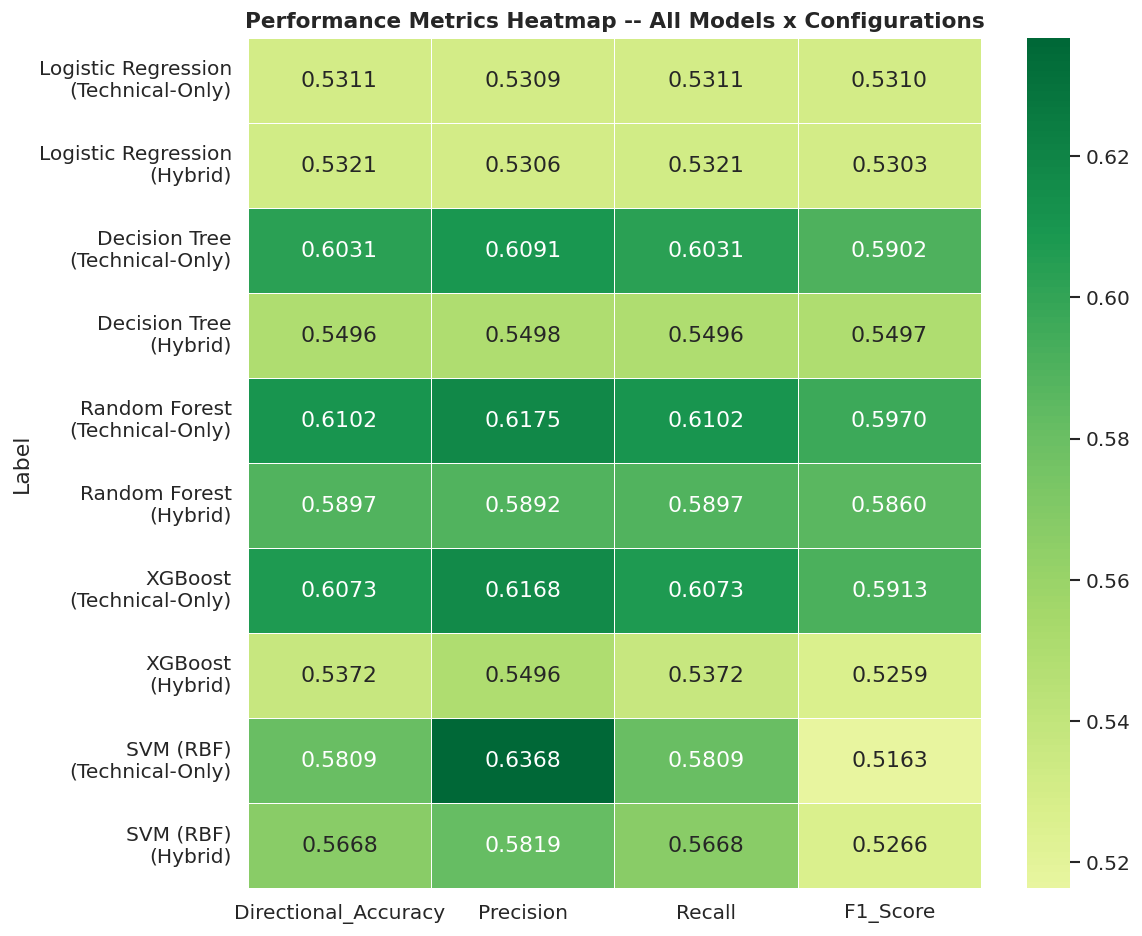

In [ ]:
# Performance Metrics Heatmap
heatmap_data = results_df.copy()
heatmap_data['Label'] = heatmap_data['Model'] + '\n(' + heatmap_data['Configuration'] + ')'
heatmap_metrics = heatmap_data[['Label', 'Directional_Accuracy', 'Precision', 'Recall', 'F1_Score']].set_index('Label')

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_metrics.astype(float), annot=True, fmt='.4f', cmap='RdYlGn', center=0.5,
            linewidths=0.5, linecolor='white')
plt.title('Performance Metrics Heatmap -- All Models x Configurations', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'metrics_heatmap.png'), bbox_inches='tight')
plt.show()

## 12. Model Saving

In [ ]:
# Create output directory
MODELS_DIR = os.path.join(OUTPUT_DIR, 'saved_models')
os.makedirs(MODELS_DIR, exist_ok=True)

# Save all trained models
print('Saving trained models...')
print(f'Output directory: {MODELS_DIR}\n')

for model_key, model_obj in models.items():
    filepath = os.path.join(MODELS_DIR, f'{model_key}.joblib')
    joblib.dump(model_obj, filepath)
    file_size = os.path.getsize(filepath) / (1024 * 1024)
    print(f'  Saved {model_key:25s} -> {filepath}  ({file_size:.1f} MB)')

# Save feature lists and metadata 
import json as json_mod
metadata = {
    'technical_features': TECHNICAL_FEATURES,
    'sentiment_features': SENTIMENT_FEATURES,
    'hybrid_features': HYBRID_FEATURES,
    'target_column': TARGET,
    'split_date': str(split_date),
    'train_shape': list(train_df.shape),
    'test_shape': list(test_df.shape),
    'model_keys': list(models.keys()),
    'svm_sample_size': SVM_SAMPLE_SIZE
}

metadata_path = os.path.join(MODELS_DIR, 'model_metadata.json')
with open(metadata_path, 'w') as f:
    json_mod.dump(metadata, f, indent=2)
print(f'\n  Saved metadata -> {metadata_path}')

# Save results DataFrames
results_path = os.path.join(OUTPUT_DIR, 'model_results.csv')
results_df.to_csv(results_path, index=False)
print(f'  Saved results  -> {results_path}')

wilcoxon_path = os.path.join(OUTPUT_DIR, 'wilcoxon_results.csv')
wilcoxon_df.to_csv(wilcoxon_path, index=False)
print(f'  Saved Wilcoxon -> {wilcoxon_path}')

print(f'\nAll {len(models)} models and metadata saved successfully!')

Saving trained models...
Output directory: /kaggle/working/saved_models

  Saved lr_technical              -> /kaggle/working/saved_models/lr_technical.joblib  (0.0 MB)
  Saved lr_hybrid                 -> /kaggle/working/saved_models/lr_hybrid.joblib  (0.0 MB)
  Saved dt_technical              -> /kaggle/working/saved_models/dt_technical.joblib  (0.4 MB)
  Saved dt_hybrid                 -> /kaggle/working/saved_models/dt_hybrid.joblib  (0.4 MB)
  Saved rf_technical              -> /kaggle/working/saved_models/rf_technical.joblib  (61.5 MB)
  Saved rf_hybrid                 -> /kaggle/working/saved_models/rf_hybrid.joblib  (65.4 MB)
  Saved xgb_technical             -> /kaggle/working/saved_models/xgb_technical.joblib  (3.8 MB)
  Saved xgb_hybrid                -> /kaggle/working/saved_models/xgb_hybrid.joblib  (3.5 MB)
  Saved svm_technical             -> /kaggle/working/saved_models/svm_technical.joblib  (3.9 MB)
  Saved svm_hybrid                -> /kaggle/working/saved_models/svm_

## 13. Verification -- Load & Test Saved Models

In [24]:
import json as json_mod
print('Verifying saved models...\n')

# Load metadata
with open(os.path.join(MODELS_DIR, 'model_metadata.json'), 'r') as f:
    loaded_metadata = json_mod.load(f)

print(f'Loaded metadata:')
print(f'  Technical features: {loaded_metadata["technical_features"]}')
print(f'  Hybrid features:    {loaded_metadata["hybrid_features"]}')
print(f'  Split date:         {loaded_metadata["split_date"]}')

# Load and test each model
print(f'\nTesting loaded models on first 100 test samples:\n')
X_sample_tech   = X_test_tech[:100]
X_sample_hybrid = X_test_hybrid[:100]

all_match = True
for model_key in loaded_metadata['model_keys']:
    loaded_model = joblib.load(os.path.join(MODELS_DIR, f'{model_key}.joblib'))
    
    # Determine which feature set to use
    if 'technical' in model_key:
        X_sample = X_sample_tech
    else:
        X_sample = X_sample_hybrid
    
    loaded_preds = loaded_model.predict(X_sample)
    original_preds = predictions[model_key][:100]
    match = np.array_equal(loaded_preds, original_preds)
    status = 'MATCH' if match else 'MISMATCH'
    if not match:
        all_match = False
    print(f'  {model_key:25s}: {status}')

print(f'\n{"="*60}')
if all_match:
    print('  ALL MODELS VERIFIED -- predictions match perfectly.')
else:
    print('  SOME MODELS DID NOT MATCH -- investigate discrepancies.')
print(f'{"="*60}')

Verifying saved models...

Loaded metadata:
  Technical features: ['Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD']
  Hybrid features:    ['Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD', 'neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity']
  Split date:         2014-01-30 00:00:00

Testing loaded models on first 100 test samples:

  lr_technical             : MATCH
  lr_hybrid                : MATCH
  dt_technical             : MATCH
  dt_hybrid                : MATCH
  rf_technical             : MATCH
  rf_hybrid                : MATCH
  xgb_technical            : MATCH
  xgb_hybrid               : MATCH
  svm_technical            : MATCH
  svm_hybrid               : MATCH

  ALL MODELS VERIFIED -- predictions match perfectly.
